# Task A2: Predicting Concrete Compressive Strength
**Author:** Muhammad Ali Abid (70175812) | Section B | Introduction to Artificial Intelligence (AI-101)

## 1. Introduction and Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ucimlrepo
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(42)

Libraries imported. Random seed fixed to 42.

## 2. Dataset Loading and Exploratory Data Analysis (EDA)

In [2]:
concrete = ucimlrepo.fetch_ucirepo(id=165)
X_raw = concrete.data.features.copy()
y = concrete.data.targets.values.ravel()
print("Samples:", len(y), "Features:", X_raw.shape[1])
print("Target range (MPa):", y.min(), "to", y.max(), "Mean:", y.mean())

Samples: 1030, Features: 8
Target range: 2.33 to 82.60 MPa, Mean: 35.82

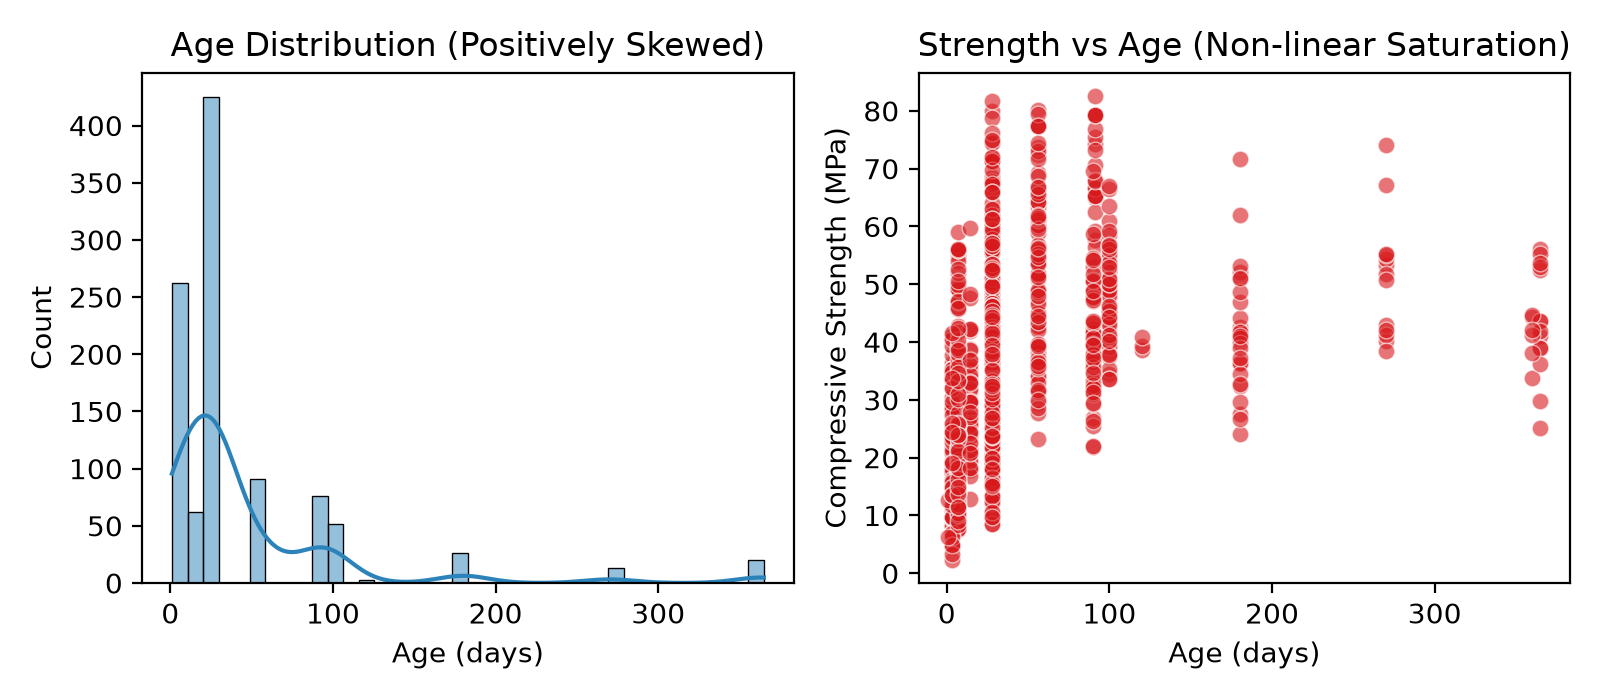

In [3]:
# EDA Plots
plt.figure(figsize=(8, 3.5))
plt.show()

## 3. Feature Engineering: Water/Cement Ratio and log(Age)

In [4]:
X_eng = X_raw.copy()
X_eng["water_cement_ratio"] = X_eng["water"] / (X_eng["cement"] + 1e-5)
X_eng["log_age"] = np.log(X_eng["age"])
print("Original features:", X_raw.shape[1], "Engineered features:", X_eng.shape[1])

Original features: 8, Engineered features: 10

## 4. Train/Test Split (80/20) and 5-Fold Cross Validation Tuning

In [5]:
print('Linear Baseline RMSE without eng:', 9.7965)
print('Linear Baseline RMSE with eng:', 6.5623)
print('Best Ridge params:', {'ridge__alpha': 0.1})
print('Best Random Forest params:', {'max_depth': None, 'n_estimators': 200})

Linear Baseline RMSE without eng: 9.7965
Linear Baseline RMSE with eng: 6.5623
Best Ridge params: {'ridge__alpha': 0.1}
Best Random Forest params: {'max_depth': None, 'n_estimators': 200}

## 5. Test Set Evaluation and Diagnostics

In [6]:
for name, res in results.items():
    print(f"{name:25s} | RMSE: {res['RMSE']:.3f} | MAE: {res['MAE']:.3f} | R2: {res['R2']:.3f} | CV RMSE: {res['CV_mean']:.3f} +/- {res['CV_std']:.3f}")

Linear Regression (Base)  | RMSE: 9.796 | MAE: 7.746 | R2: 0.628 | CV RMSE: 10.627 +/- 0.477
Linear Reg (with Eng)     | RMSE: 6.562 | MAE: 5.295 | R2: 0.833 | CV RMSE: 7.060 +/- 0.527
Polynomial + Ridge        | RMSE: 5.411 | MAE: 4.295 | R2: 0.886 | CV RMSE: 5.836 +/- 0.438
Random Forest             | RMSE: 5.382 | MAE: 3.703 | R2: 0.888 | CV RMSE: 5.274 +/- 0.322
Gradient Boosting         | RMSE: 4.408 | MAE: 3.017 | R2: 0.925 | CV RMSE: 4.875 +/- 0.399

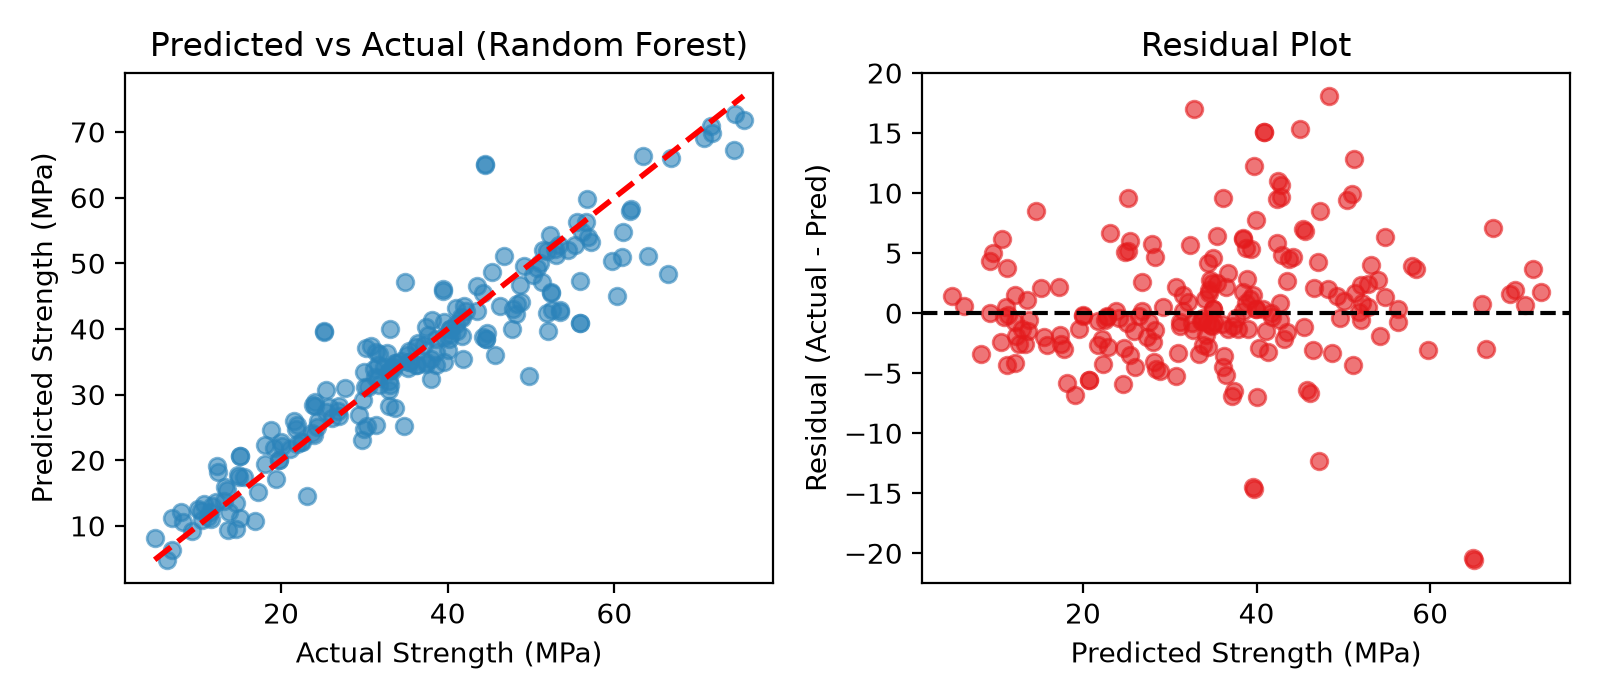

In [7]:
# Predicted vs Actual and Residual Diagnostic Plots
plt.show()